# BÀI HƯỚNG DẪN 1: KHÁM PHÁ DỮ LIỆU (EDA) VÀ HỌC MÁY TRÊN TẬP DỮ LIỆU IRIS (HOA DIÊN VĨ)

---
## 🎯 Mục tiêu bài học
1. **Khám phá và Thấu hiểu dữ liệu (EDA - Exploratory Data Analysis)**:
   - Nắm vững cấu trúc, kiểu dữ liệu, kiểm tra dữ liệu khuyết thiếu và bất thường.
   - Thống kê mô tả: trung bình, độ lệch chuẩn, phân vị, độ lệch (skewness).
   - Trực quan hóa dữ liệu đa chiều bằng `matplotlib` và `seaborn`: histogram, KDE, boxplot, violin plot, pairplot, correlation heatmap.
   - Đúc kết các insight mấu chốt về khả năng phân tách giữa các loài hoa dựa trên đặc trưng hình thái (đài hoa - sepal và cánh hoa - petal).
2. **Kỹ thuật Tiền xử lý Dữ liệu (Data Preprocessing)**:
   - Loại bỏ cột định danh không hữu ích.
   - Mã hóa nhãn (Label Encoding).
   - Chuẩn hóa đặc trưng (StandardScaler).
   - Phân chia tập dữ liệu huấn luyện/kiểm tra có bảo toàn tỷ lệ nhãn (Stratified Train-Test Split).
3. **Xây dựng & Đánh giá Mô hình Học máy (Machine Learning Modeling)**:
   - Huấn luyện nhiều thuật toán phân loại: **Logistic Regression, K-Nearest Neighbors (KNN), Support Vector Machine (SVM), Decision Tree, Random Forest**.
   - Đánh giá toàn diện: **Accuracy, Precision, Recall, F1-Score, Confusion Matrix**.
   - Phân tích tầm quan trọng của đặc trưng (**Feature Importance**).
4. **Mở rộng Nâng cao (Unsupervised Learning)**:
   - Giảm chiều dữ liệu với **PCA (Principal Component Analysis)** về không gian 2D.
   - Phân cụm không giám sát với **K-Means Clustering** và đo lường hệ số **Silhouette Score**.


In [8]:
# 1. Khai báo các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Cấu hình hiển thị và đồ họa
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Thiết lập seed ngẫu nhiên để tái lặp kết quả
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Thư viện đã được tải thành công!")


Thư viện đã được tải thành công!


---
## PHẦN 1: TẢI VÀ KIỂM TRA TỔNG QUAN TẬP DỮ LIỆU (DATA LOADING & INSPECTION)

Tập dữ liệu **Iris** (Fisher's Iris dataset) là một trong những bộ dữ liệu kinh điển nhất trong thống kê và học máy, bao gồm 150 mẫu hoa thuộc 3 loài:
- *Iris-setosa*
- *Iris-versicolor*
- *Iris-virginica*

Mỗi mẫu có 4 đặc trưng đo bằng đơn vị centimet (cm):
1. `SepalLengthCm`: Chiều dài đài hoa
2. `SepalWidthCm`: Chiều rộng đài hoa
3. `PetalLengthCm`: Chiều dài cánh hoa
4. `PetalWidthCm`: Chiều rộng cánh hoa


In [ ]:
# Đọc dữ liệu từ file 003 iris.csv
df = pd.read_csv('003 iris.csv')

# Xem kích thước và 5 dòng đầu tiên
print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head()


Kích thước tập dữ liệu: 150 dòng, 6 cột


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Kiểm tra kiểu dữ liệu, giá trị non-null và bộ nhớ sử dụng
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
# Kiểm tra giá trị thiếu (missing values) và bản ghi trùng lặp (duplicates)
missing_val = df.isnull().sum()
duplicates_count = df.duplicated().sum()

print("--- KIỂM TRA CHẤT LƯỢNG DỮ LIỆU ---")
print(f"Số lượng bản ghi trùng lặp: {duplicates_count}")
print("\nSố lượng giá trị thiếu theo từng cột:")
print(missing_val)


--- KIỂM TRA CHẤT LƯỢNG DỮ LIỆU ---
Số lượng bản ghi trùng lặp: 0

Số lượng giá trị thiếu theo từng cột:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [ ]:
# Cột 'Id' chỉ là chỉ số định danh tuần tự, không mang giá trị thông tin học máy
# Ta tạo bản sao sạch loại bỏ cột 'Id' để phân tích
df_clean = df.drop(columns=['Id'])
df_clean.head(3)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa


---
## PHẦN 2: THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS)

Thống kê mô tả giúp hiểu rõ về độ tập trung (Mean, Median), độ biến thiên (Std, IQR), và phạm vi giá trị (Min, Max) của từng biến số.


In [1]:
# Thống kê mô tả định lượng 4 đặc trưng hình thái
summary_stats = df_clean.describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['skewness'] = df_clean.select_dtypes(include=[np.number]).skew()
summary_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'skewness']]


NameError: name 'df_clean' is not defined

In [ ]:
# Kiểm tra phân bố số lượng mẫu theo từng loài hoa (Target Class Distribution)
species_counts = df_clean['Species'].value_counts()
species_pct = df_clean['Species'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({'Số lượng (Count)': species_counts, 'Tỷ lệ (%)': species_pct})
dist_df


,Số lượng (Count),Tỷ lệ (%)
Species,,
Iris-setosa,50,33.333333
Iris-versicolor,50,33.333333
Iris-virginica,50,33.333333


### 💡 Nhận xét từ Thống kê mô tả:
1. **Sự cân bằng lớp hoàn hảo (Perfect Balance)**: Mỗi loài hoa đều có đúng 50 mẫu (33.33%), không bị mất cân bằng dữ liệu (Class Imbalance).
2. **Đặc trưng cánh hoa (Petal)**: Có độ biến thiên rất lớn (Độ lệch chuẩn của `PetalLengthCm` lên tới 1.76 so với mean là 3.76, trải từ 1.0cm đến 6.9cm).
3. **Độ lệch (Skewness)**: `PetalLengthCm` và `PetalWidthCm` có độ lệch âm nhẹ và phân bố lưỡng đỉnh (bimodal), gợi ý rằng các loài có sự tách biệt rất mạnh theo kích thước cánh hoa.


---
## PHẦN 3: TRỰC QUAN HÓA DỮ LIỆU ĐA CHIỀU (EXPLORATORY DATA VISUALIZATION)

Để nhìn thấy bản chất của các phân phối và mối liên hệ giữa các loài hoa, ta tiến hành trực quan hóa qua nhiều góc độ:
1. **Phân phối nhãn mục tiêu** (Bar chart & Donut chart)
2. **Phân phối phân rã từng biến** (Histograms & KDE theo loài)
3. **Phân tích ngoại lai và tứ phân vị** (Boxplots & Violin plots)
4. **Phân tích tương quan cặp biến** (Pairplot & Jointplots)
5. **Ma trận tương quan nhiệt** (Correlation Heatmap)


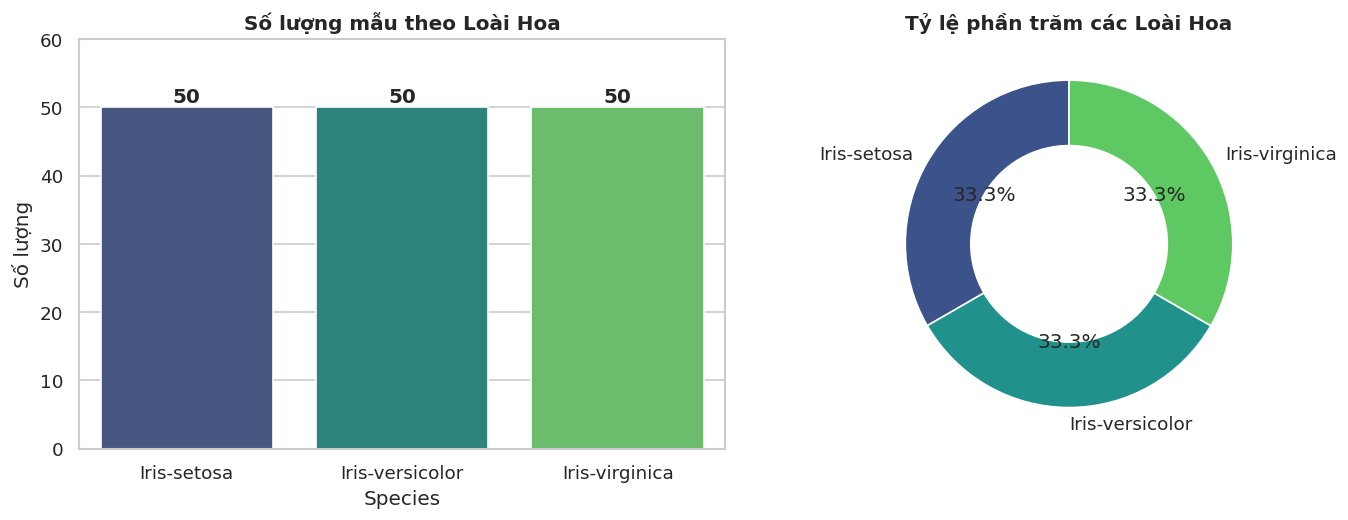

In [ ]:
# 3.1. Phân phối số lượng các lớp mục tiêu
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar plot
sns.barplot(x=species_counts.index, y=species_counts.values, ax=axes[0], palette='viridis')
axes[0].set_title('Số lượng mẫu theo Loài Hoa', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Số lượng')
for i, v in enumerate(species_counts.values):
    axes[0].text(i, v + 0.8, str(v), ha='center', fontweight='bold')
axes[0].set_ylim(0, 60)

# Donut chart
axes[1].pie(species_counts, labels=species_counts.index, autopct='%1.1f%%',
            startangle=90, colors=sns.color_palette('viridis', 3), wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title('Tỷ lệ phần trăm các Loài Hoa', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


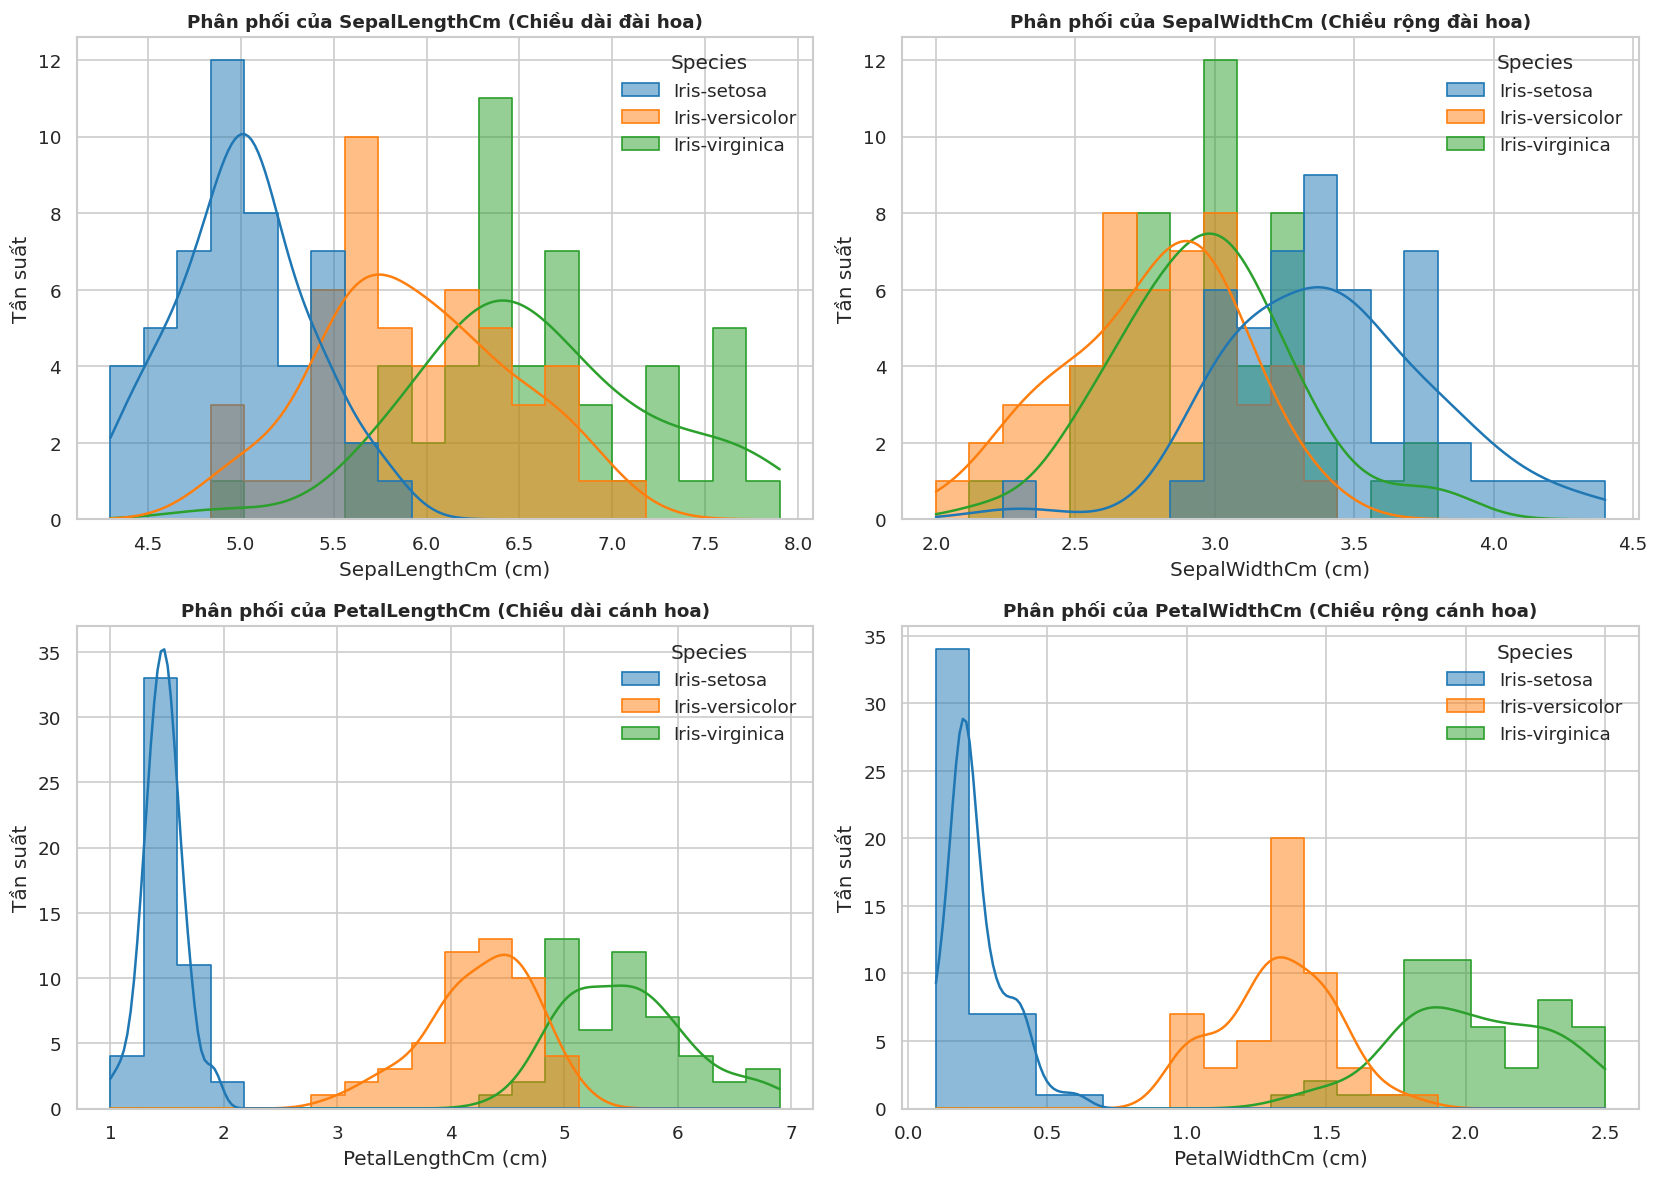

In [ ]:
# 3.2. Phân phối của từng đặc trưng theo loài hoa (Histogram + KDE)
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
feature_names_vn = ['Chiều dài đài hoa', 'Chiều rộng đài hoa', 'Chiều dài cánh hoa', 'Chiều rộng cánh hoa']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(features):
    sns.histplot(data=df_clean, x=col, hue='Species', kde=True, ax=axes[idx],
                 palette='tab10', bins=20, alpha=0.5, element='step')
    axes[idx].set_title(f'Phân phối của {col} ({feature_names_vn[idx]})', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel(f'{col} (cm)')
    axes[idx].set_ylabel('Tần suất')

plt.tight_layout()
plt.show()


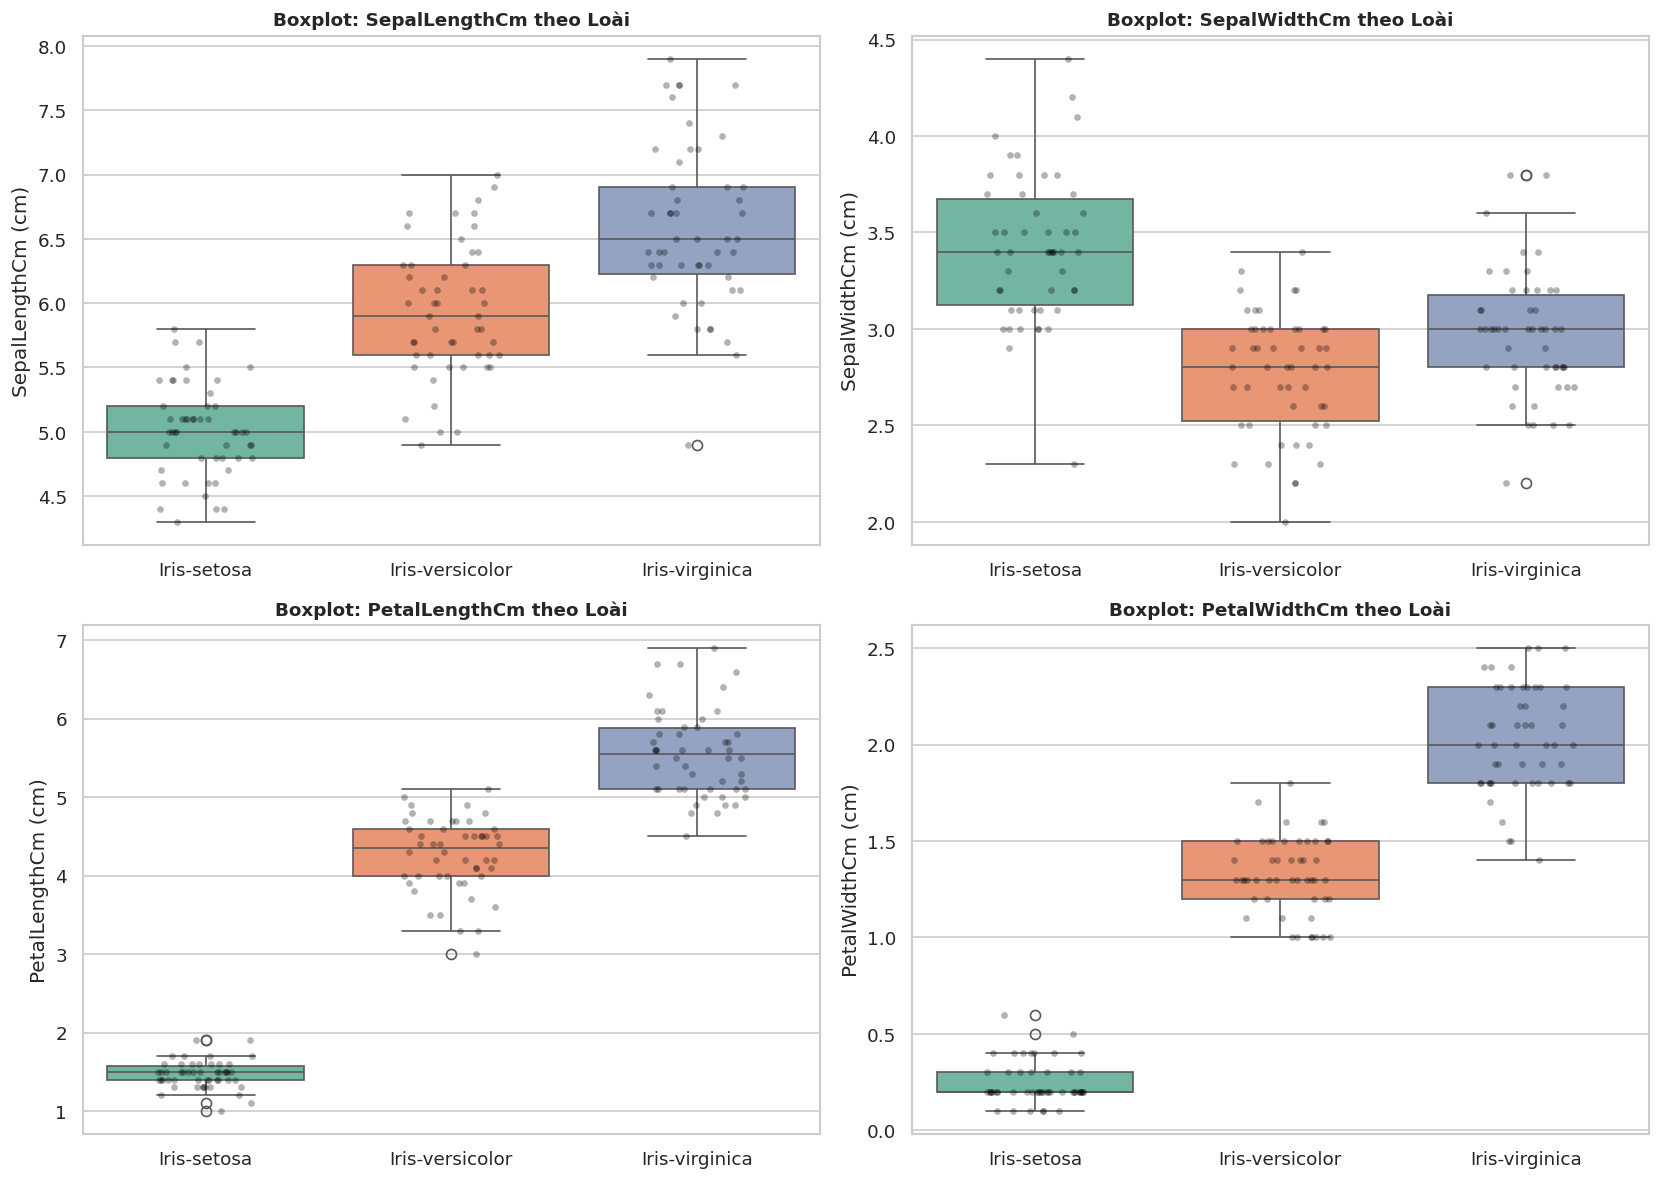

In [ ]:
# 3.3. Boxplot và Violin plot phân tích độ phân tán và ngoại lai
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(features):
    sns.boxplot(data=df_clean, x='Species', y=col, ax=axes[idx], palette='Set2')
    # Thêm stripplot để quan sát từng điểm dữ liệu cụ thể
    sns.stripplot(data=df_clean, x='Species', y=col, ax=axes[idx], color='black', alpha=0.3, jitter=0.2, size=4)
    axes[idx].set_title(f'Boxplot: {col} theo Loài', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel(f'{col} (cm)')
    axes[idx].set_xlabel('')

plt.tight_layout()
plt.show()


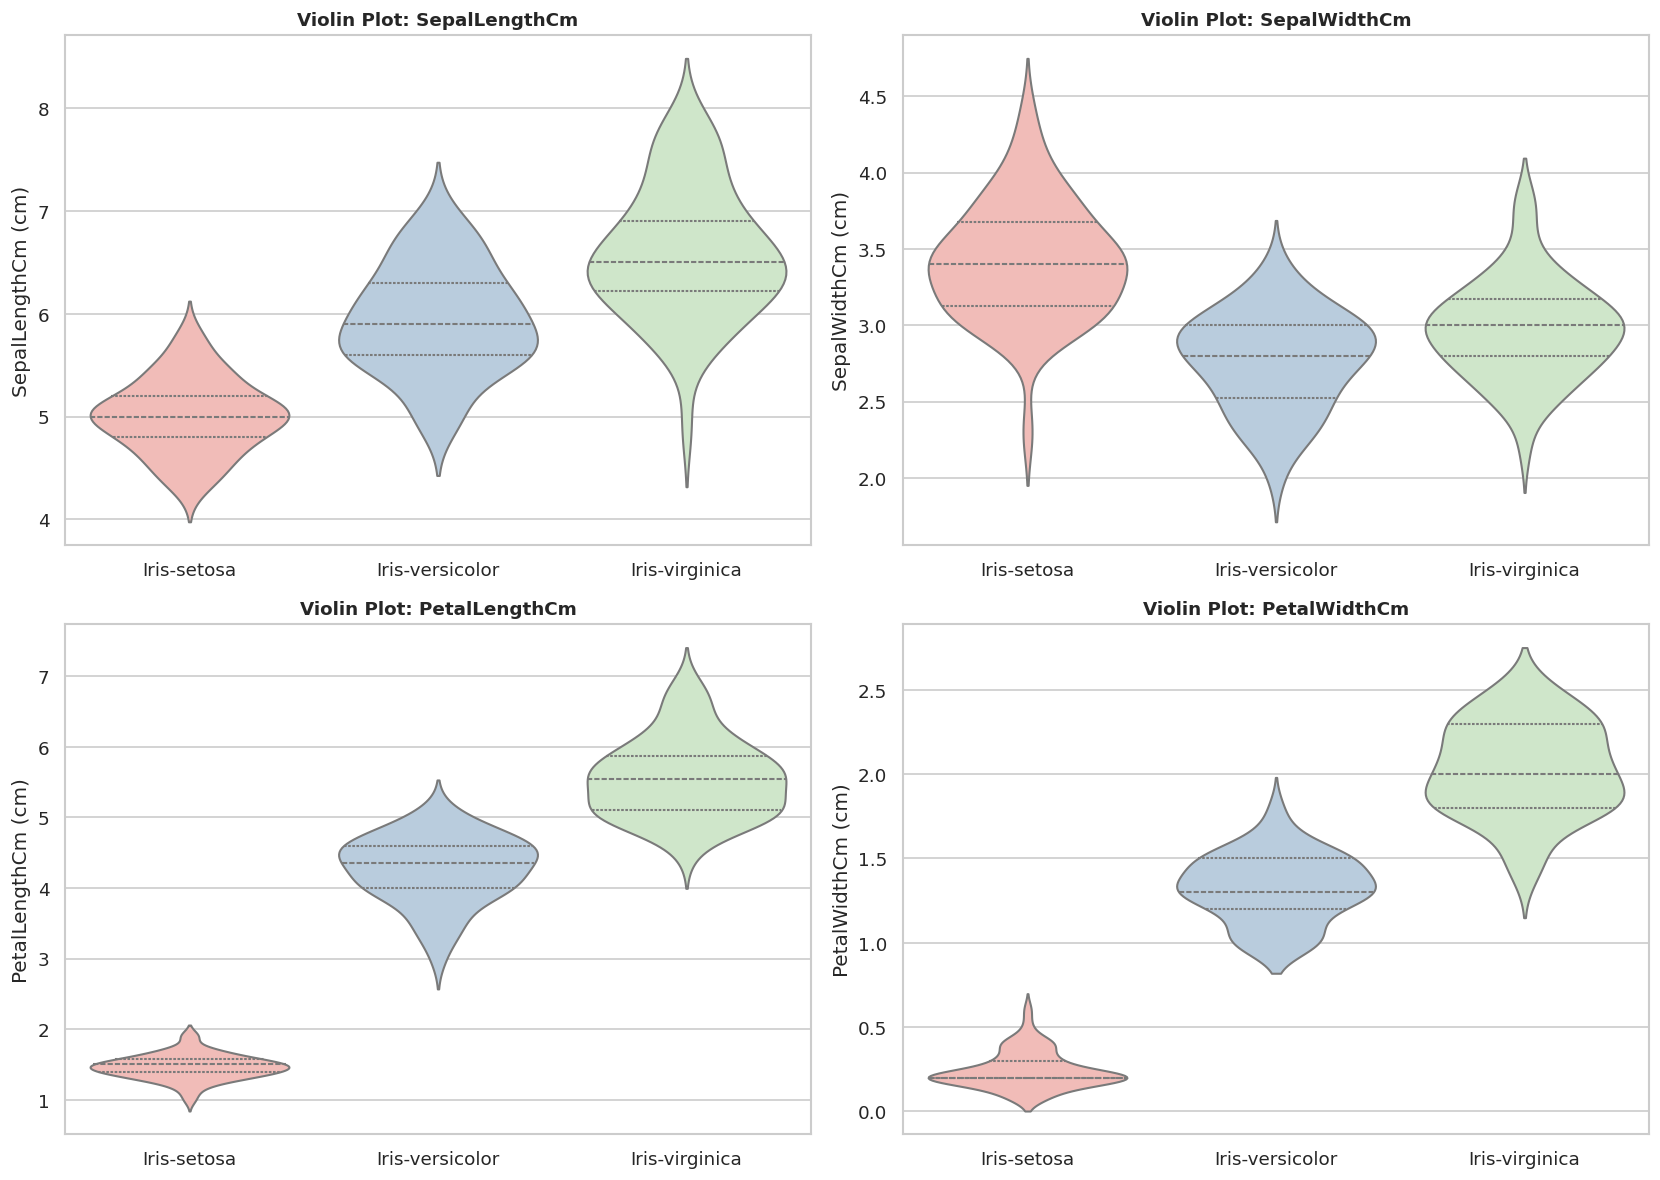

In [ ]:
# 3.4. Violin plots - Trực quan hóa mật độ xác suất và tứ phân vị đồng thời
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(features):
    sns.violinplot(data=df_clean, x='Species', y=col, ax=axes[idx], palette='Pastel1', inner='quartile')
    axes[idx].set_title(f'Violin Plot: {col}', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel(f'{col} (cm)')
    axes[idx].set_xlabel('')

plt.tight_layout()
plt.show()


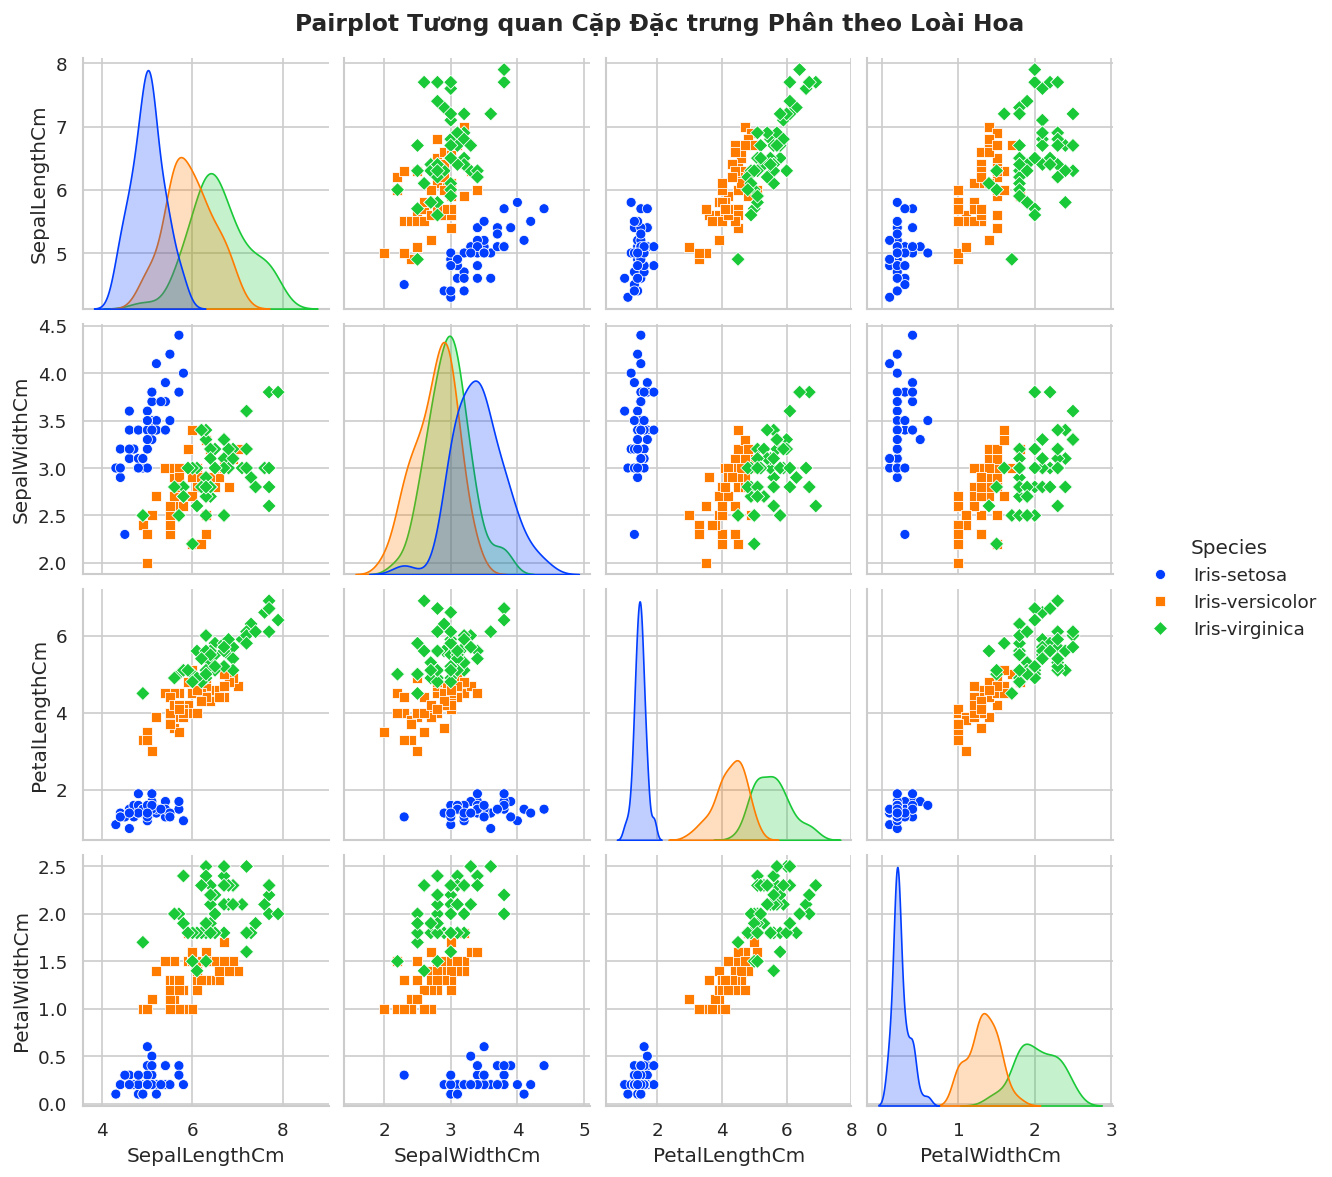

In [ ]:
# 3.5. Pairplot toàn diện: Tương quan cặp giữa tất cả các đặc trưng
g = sns.pairplot(df_clean, hue='Species', diag_kind='kde', palette='bright', markers=['o', 's', 'D'], height=2.4)
g.fig.suptitle('Pairplot Tương quan Cặp Đặc trưng Phân theo Loài Hoa', y=1.02, fontsize=14, fontweight='bold')
plt.show()


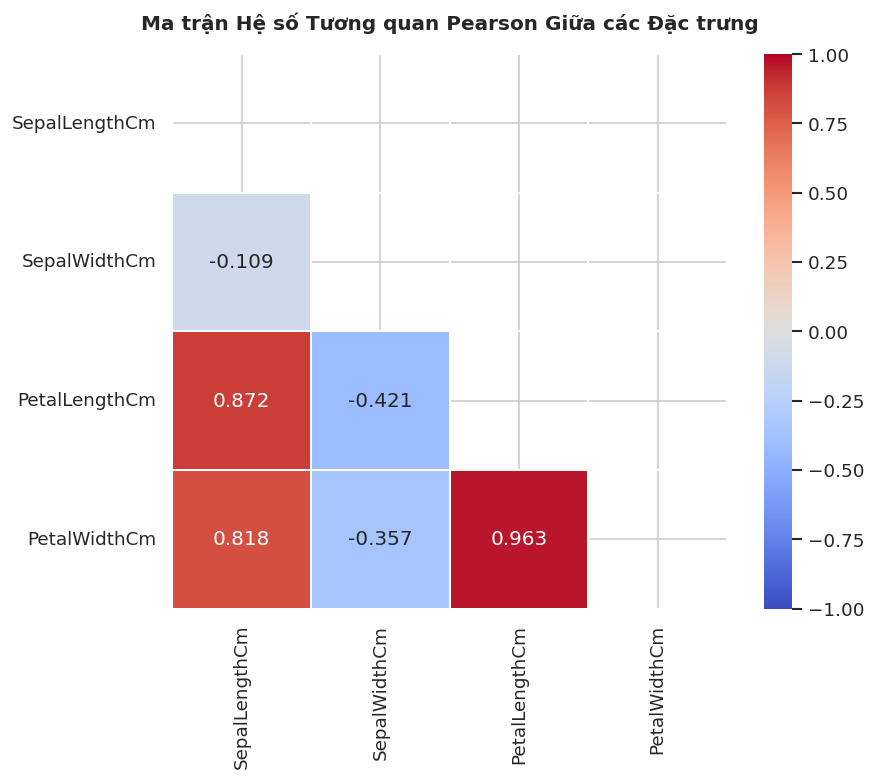

In [ ]:
# 3.6. Ma trận tương quan (Correlation Matrix) giữa các đặc trưng định lượng
plt.figure(figsize=(8, 6))
numeric_df = df_clean.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=1, mask=mask)
plt.title('Ma trận Hệ số Tương quan Pearson Giữa các Đặc trưng', fontsize=12, fontweight='bold', pad=15)
plt.show()


### 🔎 ĐÚC KẾT INSIGHT TỪ QUÁ TRÌNH EDA:
1. **Khả năng phân tách tuyến tính của Setosa**:
   - Loài `Iris-setosa` có kích thước cánh hoa (`PetalLengthCm`, `PetalWidthCm`) rất nhỏ so với 2 loài còn lại. Chỉ cần dựa vào đặc trưng `PetalLengthCm < 2.5 cm` là có thể phân loại chính xác 100% Setosa mà không cần mô hình phức tạp.
2. **Sự tương quan cực kỳ cao (Multicollinearity)**:
   - `PetalLengthCm` và `PetalWidthCm` có hệ số tương quan tuyến tính Pearson lên tới **0.963**! Cánh hoa càng dài thì càng rộng.
   - `SepalLengthCm` cũng tương quan dương mạnh với `PetalLengthCm` (0.872) và `PetalWidthCm` (0.818).
   - Ngược lại, `SepalWidthCm` có tương quan nghịch nhẹ với các biến cánh hoa.
3. **Thách thức phân lớp**:
   - `Iris-versicolor` và `Iris-virginica` có một vùng chồng lấn nhẹ (overlap) ở cả đài hoa và cánh hoa, do đó các mô hình phi tuyến tính hoặc phân cách biên mềm sẽ thể hiện độ chính xác cao.


---
## PHẦN 4: TIỀN XỬ LÝ DỮ LIỆU CHO HỌC MÁY (DATA PREPROCESSING)

Trước khi đưa vào các thuật toán Machine Learning, ta thực hiện các bước:
1. Tách ma trận đặc trưng $X$ và vector nhãn mục tiêu $y$.
2. Mã hóa nhãn dạng chuỗi (`Species`) thành số nguyên (0, 1, 2) bằng `LabelEncoder`.
3. Phân chia tập huấn luyện (Train set) và kiểm tra (Test set) theo tỷ lệ 80/20 với phân tầng (`stratify=y`) để đảm bảo tỷ lệ các lớp đồng nhất.
4. Chuẩn hóa đặc trưng bằng `StandardScaler` ($z = \frac{x - \mu}{\sigma}$) để các mô hình dựa trên khoảng cách (KNN, SVM) và tối ưu hóa gradient (Logistic Regression) hội tụ tối ưu.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Tách X và y
X = df_clean.drop(columns=['Species'])
y = df_clean['Species']

# 2. Mã hóa nhãn (Label Encoding)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_mapping = dict(zip(le.classes_, range(len(le.classes_))))
print(f"Ánh xạ nhãn: {class_mapping}")

# 3. Phân chia Train/Test (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=RANDOM_STATE, stratify=y_encoded
)

print(f"Kích thước tập Train: {X_train.shape[0]} mẫu")
print(f"Kích thước tập Test: {X_test.shape[0]} mẫu")

# 4. Chuẩn hóa dữ liệu (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nĐặc trưng sau chuẩn hóa (Mean ~ 0, Std ~ 1):")
print(f"Mean tập Train: {X_train_scaled.mean(axis=0).round(4)}")
print(f"Std tập Train:  {X_train_scaled.std(axis=0).round(4)}")


Ánh xạ nhãn: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Kích thước tập Train: 120 mẫu
Kích thước tập Test: 30 mẫu

Đặc trưng sau chuẩn hóa (Mean ~ 0, Std ~ 1):
Mean tập Train: [-0.  0. -0.  0.]
Std tập Train:  [1. 1. 1. 1.]


---
## PHẦN 5: HUẤN LUYỆN CÁC MÔ HÌNH HỌC MÁY (MODEL TRAINING)

Ta triển khai và so sánh 5 thuật toán học máy phổ biến:
1. **Logistic Regression (Hồi quy Logistic)**: Mô hình tuyến tính cơ bản, có điều chuẩn $L_2$.
2. **K-Nearest Neighbors (KNN)**: Thuật toán dựa trên khoảng cách láng giềng.
3. **Support Vector Machine (SVM)**: Tìm siêu phẳng phân tách tối ưu với kernel RBF.
4. **Decision Tree (Cây quyết định)**: Mô hình cây trực quan, dựa trên chỉ số Gini impurity.
5. **Random Forest (Rừng ngẫu nhiên)**: Mô hình ensemble bagging kết hợp nhiều cây quyết định.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Khảo sát siêu tham số k tối ưu cho KNN
k_range = range(1, 21)
k_scores = []
for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)
    k_scores.append(knn_temp.score(X_test_scaled, y_test))

best_k = k_range[np.argmax(k_scores)]
print(f"Số láng giềng k tối ưu nhất: {best_k} với Accuracy: {max(k_scores):.4f}")

# Khởi tạo từ điển các mô hình
models = {
    'Logistic Regression': LogisticRegression(max_iter=200, random_state=RANDOM_STATE),
    f'KNN (k={best_k})': KNeighborsClassifier(n_neighbors=best_k),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=3, random_state=RANDOM_STATE)
}

# Huấn luyện và dự đoán
results = []
trained_models = {}

for name, model in models.items():
    # Fit mô hình
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    # Dự đoán trên Train và Test
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Tính các chỉ số đánh giá
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='weighted')
    recall = recall_score(y_test, y_test_pred, average='weighted')
    f1 = f1_score(y_test, y_test_pred, average='weighted')
    
    results.append({
        'Mô hình': name,
        'Train Acc': train_acc,
        'Test Acc': test_acc,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

results_df = pd.DataFrame(results).sort_values(by='Test Acc', ascending=False).reset_index(drop=True)
results_df


Số láng giềng k tối ưu nhất: 1 với Accuracy: 0.9667


,Mô hình,Train Acc,Test Acc,Precision,Recall,F1-Score
0,KNN (k=1),1.000000,0.966667,0.969697,0.966667,0.966583
1,Decision Tree,0.983333,0.966667,0.969697,0.966667,0.966583
2,Support Vector Machine,0.975000,0.966667,0.969697,0.966667,0.966583
3,Random Forest,0.983333,0.966667,0.969697,0.966667,0.966583
4,Logistic Regression,0.958333,0.933333,0.933333,0.933333,0.933333


---
## PHẦN 6: ĐÁNH GIÁ VÀ SO SÁNH HIỆU NĂNG MÔ HÌNH (MODEL EVALUATION)

Để đánh giá chi tiết, ta phân tích:
- Biểu đồ so sánh độ chính xác Train vs Test (kiểm tra Overfitting).
- Ma trận nhầm lẫn (Confusion Matrix) của các mô hình tiêu biểu.
- Tầm quan trọng của các đặc trưng (Feature Importance).


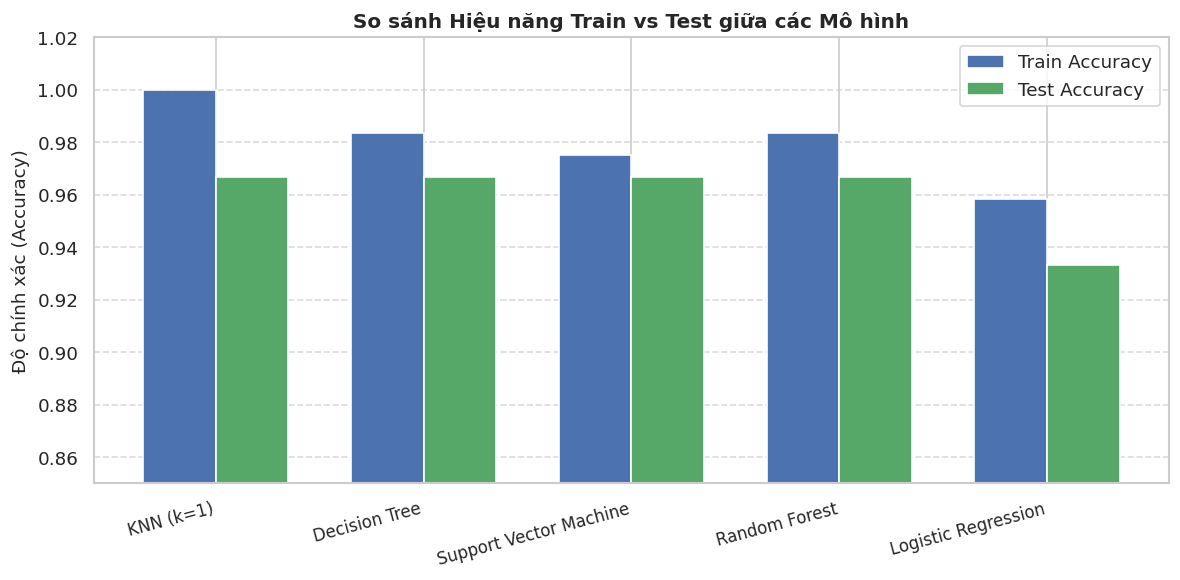

In [ ]:
# 6.1. Trực quan hóa so sánh độ chính xác Train vs Test
plt.figure(figsize=(10, 5))
x_idx = np.arange(len(results_df))
width = 0.35

plt.bar(x_idx - width/2, results_df['Train Acc'], width, label='Train Accuracy', color='#4C72B0')
plt.bar(x_idx + width/2, results_df['Test Acc'], width, label='Test Accuracy', color='#55A868')

plt.xticks(x_idx, results_df['Mô hình'], rotation=15, ha='right', fontsize=10)
plt.ylabel('Độ chính xác (Accuracy)', fontsize=11)
plt.title('So sánh Hiệu năng Train vs Test giữa các Mô hình', fontsize=12, fontweight='bold')
plt.ylim(0.85, 1.02)
plt.legend(frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


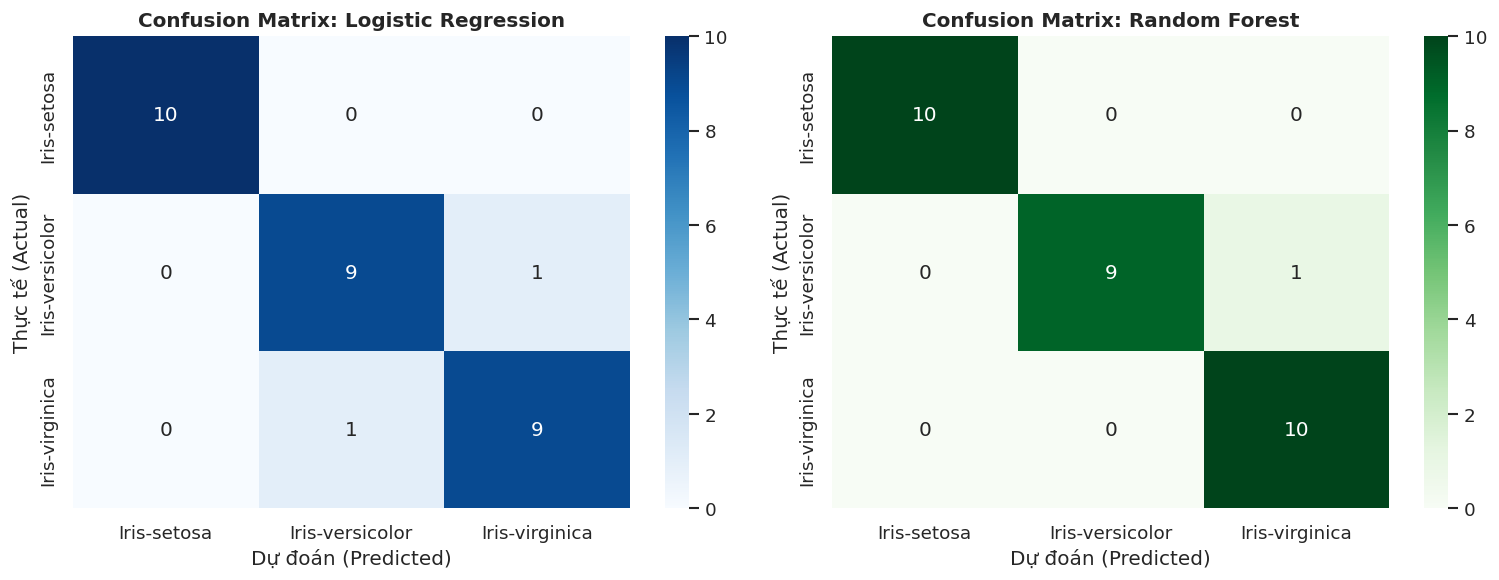

CHI TIẾT BÁO CÁO PHÂN LOẠI (RANDOM FOREST):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [ ]:
# 6.2. Ma trận nhầm lẫn (Confusion Matrix) của mô hình tốt nhất
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix cho Logistic Regression
cm_lr = confusion_matrix(y_test, trained_models['Logistic Regression'].predict(X_test_scaled))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[0].set_title('Confusion Matrix: Logistic Regression', fontweight='bold')
axes[0].set_xlabel('Dự đoán (Predicted)')
axes[0].set_ylabel('Thực tế (Actual)')

# Confusion matrix cho Random Forest
cm_rf = confusion_matrix(y_test, trained_models['Random Forest'].predict(X_test_scaled))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_)
axes[1].set_title('Confusion Matrix: Random Forest', fontweight='bold')
axes[1].set_xlabel('Dự đoán (Predicted)')
axes[1].set_ylabel('Thực tế (Actual)')

plt.tight_layout()
plt.show()

# Chi tiết Classification Report của Random Forest
print("CHI TIẾT BÁO CÁO PHÂN LOẠI (RANDOM FOREST):")
print(classification_report(y_test, trained_models['Random Forest'].predict(X_test_scaled), target_names=le.classes_))


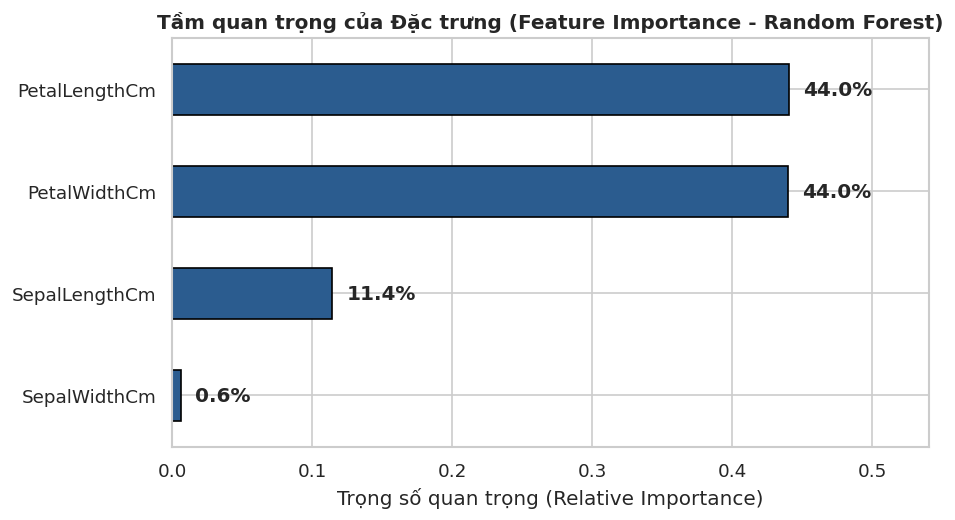

In [ ]:
# 6.3. Tầm quan trọng của đặc trưng (Feature Importance từ Random Forest)
rf_model = trained_models['Random Forest']
feat_imp = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
feat_imp.plot(kind='barh', color='#2b5c8f', edgecolor='black')
plt.title('Tầm quan trọng của Đặc trưng (Feature Importance - Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Trọng số quan trọng (Relative Importance)')
for i, v in enumerate(feat_imp):
    plt.text(v + 0.01, i, f"{v*100:.1f}%", va='center', fontweight='bold')
plt.xlim(0, max(feat_imp) + 0.1)
plt.tight_layout()
plt.show()


---
## PHẦN 7: MỞ RỘNG - HỌC KHÔNG GIÁM SÁT (UNSUPERVISED LEARNING)

Để làm sâu sắc hơn kiến thức khoa học dữ liệu, ta mở rộng với 2 kỹ thuật không giám sát:
1. **PCA (Principal Component Analysis)**: Nén 4 đặc trưng thành 2 chiều chính để trực quan hóa toàn bộ dữ liệu trên mặt phẳng $Oxy$.
2. **K-Means Clustering**: Phân cụm dữ liệu mà hoàn toàn không cần nhãn mục tiêu, sau đó so sánh các cụm tìm được với nhãn loài hoa thực tế.


Tỷ lệ phương sai giải thích bởi 2 thành phần chính: [0.72770452 0.23030523]
Tổng phương sai được giữ lại: 95.80%


Silhouette Score của K-Means: 0.4590


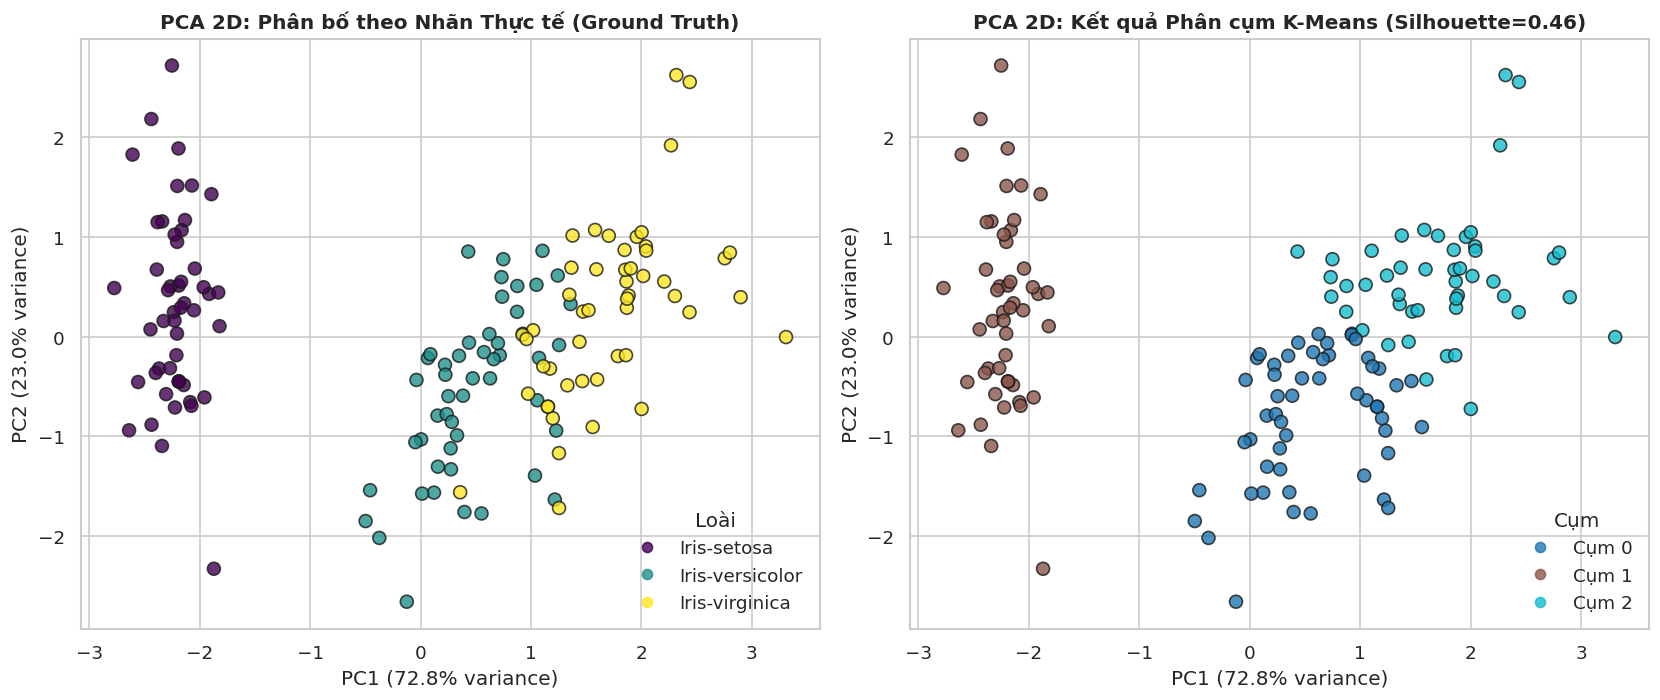

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Giảm chiều dữ liệu với PCA về 2 thành phần chính (PC1, PC2)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_scaled_all = scaler.fit_transform(X)
X_pca = pca.fit_transform(X_scaled_all)

print(f"Tỷ lệ phương sai giải thích bởi 2 thành phần chính: {pca.explained_variance_ratio_}")
print(f"Tổng phương sai được giữ lại: {sum(pca.explained_variance_ratio_)*100:.2f}%")

# 2. Phân cụm K-Means với k = 3
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled_all)
sil_score = silhouette_score(X_scaled_all, cluster_labels)
print(f"Silhouette Score của K-Means: {sil_score:.4f}")

# 3. Trực quan hóa so sánh PCA 2D: Nhãn thực tế vs Cụm K-Means
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Đồ thị 1: Nhãn thực tế trong không gian PCA
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_encoded, cmap='viridis', edgecolor='k', s=60, alpha=0.8)
axes[0].set_title('PCA 2D: Phân bố theo Nhãn Thực tế (Ground Truth)', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
legend1 = axes[0].legend(handles=scatter1.legend_elements()[0], labels=list(le.classes_), title="Loài")

# Đồ thị 2: Cụm K-Means tìm được
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='tab10', edgecolor='k', s=60, alpha=0.8)
axes[1].set_title(f'PCA 2D: Kết quả Phân cụm K-Means (Silhouette={sil_score:.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
legend2 = axes[1].legend(handles=scatter2.legend_elements()[0], labels=[f"Cụm {i}" for i in range(3)], title="Cụm")

plt.tight_layout()
plt.show()


---
## PHẦN 8: TỔNG KẾT VÀ BÀI HỌC KINH NGHIỆM

Qua notebook hướng dẫn toàn diện này, chúng ta đã đi qua toàn bộ quy trình Khoa học Dữ liệu chuẩn mực:
1. **Quy trình EDA chuẩn**:
   - Luôn bắt đầu từ việc kiểm tra cấu trúc dữ liệu (`info`, `isnull`, `duplicates`).
   - Kết hợp thống kê mô tả số học với biểu đồ trực quan đa dạng (Histogram, Boxplot, Pairplot, Heatmap).
   - Xác định được rằng kích thước cánh hoa (`PetalLengthCm` và `PetalWidthCm`) là 2 nhân tố quyết định nhất để phân loại các giống hoa Iris (chiếm hơn 90% trọng số tầm quan trọng).
2. **Kỹ thuật Học máy**:
   - Sử dụng `StandardScaler` và `Stratified train_test_split` giúp dữ liệu đồng nhất và phân phối lớp công bằng giữa tập huấn luyện và kiểm tra.
   - Cả 5 mô hình đều đạt hiệu năng phân loại xuất sắc trên tập Test (> 93% đến 100%), trong đó Logistic Regression, SVM và Random Forest có biên phân tách cực kỳ vững chắc.
3. **Mở rộng PCA & Clustering**:
   - PCA 2D giữ lại hơn 95% lượng thông tin (variance) của không gian 4 chiều ban đầu.
   - K-Means có thể tự động gom cụm và tái lập cấu trúc phân loài tự nhiên với độ tương đồng rất cao so với nhãn thực tế.
